In [ ]:
# Ogólne
import os
import re
import cv2
import json
import logging
import random
import warnings
from typing import Dict, Any
from dataclasses import dataclass
from difflib import SequenceMatcher

# Biblioteki Data Science
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna  

# Scikit-learn 
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.utils import murmurhash3_32
from sklearn.metrics import confusion_matrix
# PyTorch i Torchvision 
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# OCR i przetwarzanie obrazu 
from PIL import Image
import pytesseract

# Konfiguracja logowania i wyłączenie ostrzeżeń
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')

# Konfiguracja ścieżki do Tesseract (Wymagane na Windows)
#pytesseract.pytesseract.tesseract_cmd = r'D:\Program Files\Tesseract-OCR\tesseract.exe'


# Baza danych #


In [21]:
baza_produktow = {
    0: [ # NABIAŁ (0)
        "Mleko Pilos 2%", "Mleko Pilos 3.2%", "Mleko Łaciate", "Mleko Mlekovita", "Mleko Wypasione",
        "Masło Ekstra", "Masło Osełka", "Masło Kerrygold", "Masło Polskie", "Masło Klarowane",
        "Margaryna Rama", "Margaryna Delma", "Margaryna Kasia", "Flora", "Mix tłuszczowy",
        "Serek Wiejski Pątnica", "Serek Wiejski Pilos", "Serek Almette", "Serek Hochland",
        "Ser Żółty Gouda", "Ser Edamski", "Ser Królewski", "Ser Morski", "Ser Mozzarella",
        "Jogurt Naturalny", "Jogurt Zott", "Jogurt Fantasia", "Jogurt Bakoma", "Jogurt Grecki",
        "Śmietana 18%", "Śmietana 12%", "Śmietanka 30%", "Kefir Robico", "Maślanka Mrągowska",
        "Ser Camembert", "Ser Brie", "Ser Feta", "Ser Mascarpone", "Twaróg Półtłusty", "Twaróg Chudy"
    ],
    1: [ # PIECZYWO (1)
        "Chleb Baltonowski", "Chleb Razowy", "Chleb Żytni", "Chleb Wiejski", "Chleb Tostowy",
        "Bułka Kajzerka", "Bułka Grahamka", "Bułka Poznańska", "Bułka z Dynią", "Bułka Serowa",
        "Bagietka Czosnkowa", "Półbagietka", "Ciabatta", "Rogal Maślany", "Drożdżówka z serem",
        "Pączek", "Chleb Słonecznikowy", "Bułka Tarta", "Tortilla", "Pita", "Podpłomyk"
    ],
    2: [ # WARZYWA/OWOCE (2)
        "Banany Luz", "Jabłka Polskie", "Jabłka Jonagold", "Cytryna Luz", "Pomarańcze Siatka",
        "Pomidory Gałązka", "Pomidor Malinowy", "Ogórek Szklarniowy", "Ogórek Gruntowy",
        "Ziemniaki Myte", "Ziemniaki Wczesne", "Marchew Luz", "Cebula Żółta", "Cebula Czerwona",
        "Papryka Czerwona", "Papryka Żółta", "Pieczarki", "Sałata Lodowa", "Sałata Masłowa",
        "Rzodkiewka Pęczek", "Kapusta Biała", "Czosnek", "Awokado Hass", "Truskawki", "Borówki",
        "Arbuz", "Mandarynki", "Winogrona Jasne", "Brokuł", "Kalafior", "Cukinia"
    ],
    3: [ # MIĘSO/WĘDLINY/RYBY (3)
        "Filet z Kurczaka", "Pierś z Kurczaka", "Udka z Kurczaka", "Skrzydełka", "Kurczak Cały",
        "Mięso Mielone Wieprzowe", "Mięso Mielone z Szynki", "Mięso Mielone Wołowe",
        "Schab Bez Kości", "Karkówka Wieprzowa", "Boczek Surowy", "Boczek Wędzony",
        "Szynka Konserwowa", "Szynka Babuni", "Polędwica Sopocka", "Kiełbasa Śląska", "Kiełbasa Podwawelska",
        "Kiełbasa Żywiecka", "Parówki Berlinki", "Parówki Tarczyński", "Kabanosy", "Salami",
        "Łosoś Wędzony", "Filet z Dorsza", "Makrela Wędzona", "Śledzie w Oleju", "Śledzie w Śmietanie"
    ],
    4: [ # PRZEKĄSKI/SŁODYCZE (4)
        "Chipsy Lays Solone", "Chipsy Lays Papryka", "Chipsy Zielona Cebulka", "Chipsy Wiejskie Ziemniaczki",
        "Chipsy Pringles", "Chrupki Cheetos", "Orzeszki Ziemne Felix", "Orzeszki Solone",
        "Baton Snickers", "Baton Mars", "Baton Twix", "Baton KitKat", "Baton Lion", "Baton Prince Polo",
        "Czekolada Milka", "Czekolada Wedel", "Czekolada Gorzka", "Czekolada Mleczna",
        "Kinder Bueno", "Kinder Niespodzianka", "Żelki Haribo", "Żelki Śmiejżelki",
        "Ciastka Delicje", "Ciastka Jeżyki", "Herbatniki Petit", "Wafelki Góralki", "Paluszki Lajkonik"
    ],
    5: [ # NAPOJE (5)
        "Woda Żywiec Zdrój", "Woda Cisowianka", "Woda Muszynianka", "Woda Nałęczowianka",
        "Coca Cola 1L", "Coca Cola Zero", "Pepsi", "Fanta", "Sprite", "Mirinda",
        "Sok Tymbark Jabłko", "Sok Tymbark Pomarańcza", "Sok Hortex", "Nektar Bananowy",
        "Napój Energetyczny Tiger", "Red Bull", "Monster Energy", "Black Energy",
        "Ice Tea Lipton", "Herbata Nestea", "Woda Gazowana", "Woda Niegazowana"
    ],
    6: [ # INNE/SYPKIE/TŁUSZCZE/OBIADY (6)
        "Mąka Pszenna", "Mąka Tortowa", "Mąka Lubella", "Cukier Biały", "Cukier Puder", "Sól Kamienna",
        "Ryż Biały", "Ryż Jaśminowy", "Kasza Gryczana", "Kasza Jęczmienna", "Makaron Spaghetti",
        "Makaron Świderki", "Makaron Lubella", "Olej Kujawski", "Olej Rzepakowy", "Oliwa z Oliwek",
        "Ocet Spirytusowy", "Musztarda Sarepska", "Musztarda Kamis", "Ketchup Pudliszki", "Ketchup Kotlin",
        "Ketchup Włocławek", "Majonez Winiary", "Majonez Kielecki", "Sos Boloński", "Sos Słodko-Kwaśny",
        "Zupa w Proszku", "Danie w Słoiku", "Fasolka po Bretońsku", "Pulpety w Sosie", "Pizza Mrożona Guseppe"
    ],
    7: [ # ALKOHOL (7)
        "Piwo Tyskie", "Piwo Żywiec", "Piwo Lech", "Piwo Harnaś", "Piwo Żubr", "Piwo Kasztelan",
        "Piwo Warka", "Piwo Perła", "Piwo Desperados", "Piwo Somersby", "Piwo Carlsberg",
        "Piwo Heineken", "Piwo Namysłów", "Piwo Łomża", "Wódka Żubrówka", "Wódka Wyborowa",
        "Wódka Soplica", "Wódka Finlandia", "Wino Czerwone", "Wino Białe", "Wino Musujące",
        "Whisky Jack Daniels", "Whisky Ballantines"
    ]
}

In [22]:
# SYMULATOR "ŹLE ODCZYTANEGO PARAGONU" I GENERACJA PLIKU 

def zrob_paragon(tekst):
    # Wielkie litery
    tekst = tekst.upper()
    
    # Korekta Polskich znaków
    replacements = {
        'Ą': 'A', 'Ć': 'C', 'Ę': 'E', 'Ł': 'L', 'Ń': 'N', 
        'Ó': 'O', 'Ś': 'S', 'Ź': 'Z', 'Ż': 'Z'
    }
    for pl, ang in replacements.items():
        tekst = tekst.replace(pl, ang)
        
    # Symulacja skrótowych zapisów na pragonach
    slowa = tekst.split()
    nowe_slowa = []
    for slowo in slowa:
        if len(slowo) > 4 and random.random() > 0.6: # Losowanie miejsca ucięcia
            ciecie = random.randint(3, len(slowo)-1)
            nowe_slowa.append(slowo[:ciecie] + ".")
        else:
            nowe_slowa.append(slowo)
            
    tekst = " ".join(nowe_slowa)
    
    #  Dodajemy nadmiarowo zczytane końcówki
    if random.random() > 0.5:
        tekst += " A" # Kod podatkowy
    if random.random() > 0.7:
        tekst = tekst + " " + str(random.choice(["1L", "200G", "500G", "PAK"]))
        
    return tekst

# GENEROWANIE PLIKU CSV 
data = []
print("Generowanie sztucznych paragonów: ")

for label, products in baza_produktow.items():
    for prod in products:
        data.append([prod, label]) # Dodajemy oryginał
        
        # Dodajemy 30 wariacji "paragonowych" z błędami dla każdego produktu
        for i in range(30):
            data.append([zrob_paragon(prod), label])

# Mieszamy dane, żeby sieć nie uczyła się po kolei
random.shuffle(data)

# Tworzymy DataFrame i zapisujemy do pliku
df_lidl = pd.DataFrame(data, columns=['text', 'label'])
df_lidl.to_csv("dataset_lidl.csv", index=False)

print(f"Sukces! Stworzono bazę: {len(df_lidl)} rekordów i zapisano jako 'dataset_lidl.csv'.")

Generowanie sztucznych paragonów: 
Sukces! Stworzono bazę: 6882 rekordów i zapisano jako 'dataset_lidl.csv'.


# Wczytanie danych #

In [23]:
df = pd.read_csv('dataset_lidl.csv')
df.head()

,text,label
0,KAPUSTA BIA. 500G,2
1,HERBATA NESTEA A 200G,5
2,POMARANCZE SIATKA A 200G,2
3,MAKA LUBEL. A,6
4,COCA COLA 1L,5


# Trening i Fine-Tunning dla Sieci Neuronowej #

In [24]:
K_FOLDS = 3 # Liczba foldów w crosswalidacji
N_TRIALS = 15 # Ile różnych kombinacji Optuna ma przetestować

class SiecNeuronowa(nn.Module):
    def __init__(self, n_features, hidden_size, dropout_rate):
        super().__init__()
        self.fc1 = nn.Linear(n_features, hidden_size)
        self.bn1 = nn.BatchNorm1d(hidden_size)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate) 
        self.fc2 = nn.Linear(hidden_size, 8)

    def forward(self, x):
        if x.dim() == 1: x = x.unsqueeze(0)
        x = self.fc1(x)
        if x.size(0) > 1: x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x


# PRE-WEKTORYZACJA 
print("Pre-wektoryzacja danych dla Optuny ")

def text_to_vector(text, input_size):
    text = str(text).lower().strip()
    vector = torch.zeros(input_size)
    if len(text) < 3: text += "   " 
    for i in range(len(text) - 2):
        trigram = text[i:i+3]
        idx = murmurhash3_32(trigram, seed=42) % input_size
        vector[idx] += 1.0
    return vector

y = torch.tensor(df['label'].values, dtype=torch.long)
dane_dla_wymiarow = {}
wymiary_do_sprawdzenia = [3000, 5000]

for n_feat in wymiary_do_sprawdzenia:
    X_lista = [text_to_vector(t, input_size=n_feat) for t in df['text']]
    X_temp = torch.stack(X_lista)
    
    X_train_full_np, X_test_np, y_train_full_np, y_test_np = train_test_split(
        X_temp.numpy(), y.numpy(), test_size=0.2, random_state=42, stratify=y.numpy()
    )
    
    dane_dla_wymiarow[n_feat] = {
        'X_train_full': X_train_full_np,
        'y_train_full': y_train_full_np,
        'X_test': torch.from_numpy(X_test_np),
        'y_test': torch.from_numpy(y_test_np)
    }

print("Dane przygotowane. Teraz szukamy najlepszych hiperparametrów:\n")

#  DEFINICJA FUNKCJI CELU DLA OPTUNY 
def objective(trial):
    n_features = trial.suggest_categorical('n_features', wymiary_do_sprawdzenia)
    hidden_size = trial.suggest_categorical('hidden_size', [64, 128, 256])
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True) 
    batch_size = trial.suggest_categorical('batch_size', [32, 64])
    epochs = trial.suggest_int('epochs', 15, 30)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.4) 
    
    # Pobieramy odpowiednie dane z pamięci
    obecne_dane = dane_dla_wymiarow[n_features]
    X_train_full_np = obecne_dane['X_train_full']
    y_train_full_np = obecne_dane['y_train_full']
    
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    fold_accs = []
    
    for train_idx, val_idx in skf.split(X_train_full_np, y_train_full_np):
        X_train_fold = torch.from_numpy(X_train_full_np[train_idx])
        y_train_fold = torch.from_numpy(y_train_full_np[train_idx])
        X_val_fold = torch.from_numpy(X_train_full_np[val_idx])
        y_val_fold = torch.from_numpy(y_train_full_np[val_idx])
        
        train_ds = TensorDataset(X_train_fold, y_train_fold)
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True)
        
        _, counts = np.unique(y_train_fold.numpy(), return_counts=True)
        wagi_tensor = torch.FloatTensor(1.0 / counts / (1.0 / counts).sum())

        model_cv = SiecNeuronowa(n_features=n_features, hidden_size=hidden_size, dropout_rate=dropout_rate)
        criterion = nn.CrossEntropyLoss(weight=wagi_tensor)
        optimizer = optim.Adam(model_cv.parameters(), lr=lr)
        
        for epoch in range(epochs):
            model_cv.train()
            for inputs, labels in train_loader:
                optimizer.zero_grad()
                loss = criterion(model_cv(inputs), labels)
                loss.backward()
                optimizer.step()
                
        model_cv.eval()
        with torch.no_grad():
            _, predicted = torch.max(model_cv(X_val_fold).data, 1)
            correct = (predicted == y_val_fold).sum().item()
            acc = 100 * correct / len(y_val_fold)
            fold_accs.append(acc)
            
    # Zwracamy średnią z K-Fold. Optuna będzie dążyć do jej zmaksymalizowania
    return np.mean(fold_accs)

# URUCHOMIENIE OPTUNY W CELU MAXYMALIZACJI WYNIKU
optuna.logging.set_verbosity(optuna.logging.INFO)
study = optuna.create_study(direction="maximize", study_name="Paragon_OCR_Tuning")
study.optimize(objective, n_trials=N_TRIALS)

print("\n" + "="*50)
print("ZWYCIĘZCA WEDŁUG OPTUNY:")
print(f"Parametry: {study.best_params}")
print(f"Średnia Dokładność CV: {study.best_value:.2f}%")
print("="*50)


# OSTATECZNY TRENING I ZAPIS MODELU
print("\nTrenowanie ostatecznego modelu na CAŁYCH danych treningowych z wygranymi parametrami ")

best_params = study.best_params

wygrane_dane = dane_dla_wymiarow[best_params['n_features']]
X_train_full = torch.from_numpy(wygrane_dane['X_train_full'])
y_train_full = torch.from_numpy(wygrane_dane['y_train_full'])
X_test = wygrane_dane['X_test']
y_test = wygrane_dane['y_test']

final_ds = TensorDataset(X_train_full, y_train_full)
final_loader = DataLoader(final_ds, batch_size=best_params['batch_size'], shuffle=True, drop_last=True)

_, counts_full = np.unique(y_train_full.numpy(), return_counts=True)
wagi_tensor_full = torch.FloatTensor(1.0 / counts_full / (1.0 / counts_full).sum())

final_model = SiecNeuronowa(
    n_features=best_params['n_features'], 
    hidden_size=best_params['hidden_size'],
    dropout_rate=best_params['dropout_rate']
)
criterion = nn.CrossEntropyLoss(weight=wagi_tensor_full)
optimizer = optim.Adam(final_model.parameters(), lr=best_params['lr'])

# STRATY DLA KOLEJNYCH EPOK
train_losses = [] 

for epoch in range(best_params['epochs']):
    final_model.train()
    running_loss = 0.0 # Zerujemy licznik na start epoki
    
    for inputs, labels in final_loader:
        optimizer.zero_grad()
        outputs = final_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() # Dodajemy loss z każdej paczki
        
    # Uśredniamy stratę dla całej epoki i dorzucamy do listy
    avg_epoch_loss = running_loss / len(final_loader)
    train_losses.append(avg_epoch_loss)

# SPRAWDZIAN NA ZBIORZE TESTOWYM
final_model.eval()
with torch.no_grad():
    _, predicted = torch.max(final_model(X_test).data, 1)
    ostateczny_wynik = 100 * (predicted == y_test).sum().item() / len(y_test)

print(f"\nOSTATECZNY WYNIK NA ZBIORZE TESTOWYM: {ostateczny_wynik:.2f}% ")

# Zapis 1: Wagi
torch.save(final_model.state_dict(), 'model_paragonowy.pth')
print("Wagi zapisane jako 'model_paragonowy.pth'")

# Zapis 2: Konfiguracja 
with open('model_config.json', 'w') as f:
    json.dump(best_params, f)
print("Konfiguracja zapisana jako 'model_config.json'")

model = final_model

Pre-wektoryzacja danych dla Optuny 


[I 2026-02-27 19:50:42,427] A new study created in memory with name: Paragon_OCR_Tuning


Dane przygotowane. Teraz szukamy najlepszych hiperparametrów:



[I 2026-02-27 19:51:19,845] Trial 0 finished with value: 99.87284287011808 and parameters: {'n_features': 3000, 'hidden_size': 256, 'lr': 0.001897810397693823, 'batch_size': 32, 'epochs': 18, 'dropout_rate': 0.34743292520804137}. Best is trial 0 with value: 99.87284287011808.
[I 2026-02-27 19:51:43,552] Trial 1 finished with value: 99.81834695731153 and parameters: {'n_features': 5000, 'hidden_size': 64, 'lr': 0.001618969718658515, 'batch_size': 32, 'epochs': 20, 'dropout_rate': 0.12220285844490231}. Best is trial 0 with value: 99.87284287011808.
[I 2026-02-27 19:52:57,443] Trial 2 finished with value: 99.90917347865576 and parameters: {'n_features': 5000, 'hidden_size': 256, 'lr': 0.004458264574112735, 'batch_size': 32, 'epochs': 24, 'dropout_rate': 0.21784615692013196}. Best is trial 2 with value: 99.90917347865576.
[I 2026-02-27 19:53:46,131] Trial 3 finished with value: 99.85467756584922 and parameters: {'n_features': 5000, 'hidden_size': 256, 'lr': 0.009749803287934681, 'batch_siz


ZWYCIĘZCA WEDŁUG OPTUNY:
Parametry: {'n_features': 5000, 'hidden_size': 128, 'lr': 0.00047979223158972997, 'batch_size': 64, 'epochs': 15, 'dropout_rate': 0.3756709687989547}
Średnia Dokładność CV: 99.96%

Trenowanie ostatecznego modelu na CAŁYCH danych treningowych z wygranymi parametrami 

OSTATECZNY WYNIK NA ZBIORZE TESTOWYM: 99.93% 
Wagi zapisane jako 'model_paragonowy.pth'
Konfiguracja zapisana jako 'model_config.json'


# Wykres zbieżności funkcji straty #

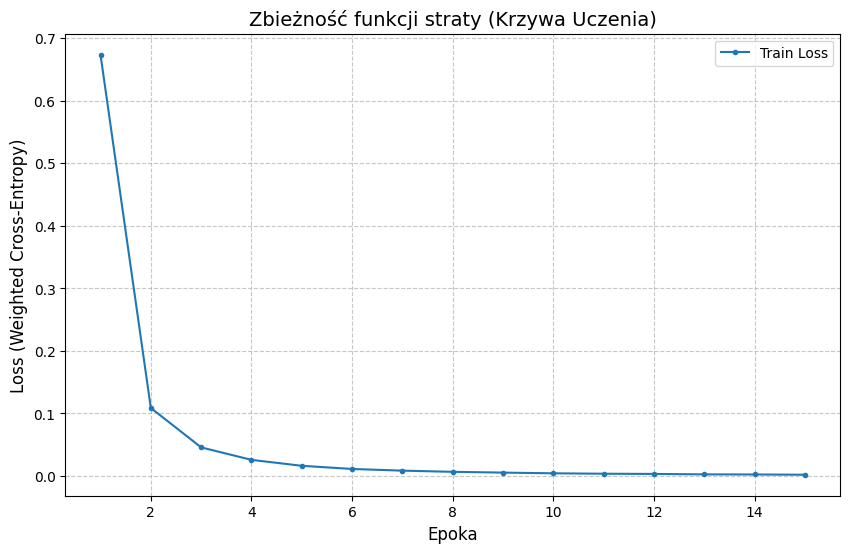

In [25]:
# Tworzymy listę z numerami epok 
epoki = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 6))
# Wykres zbieżności funkcji straty
plt.plot(epoki, train_losses, marker='.', linestyle='-', color='#1f77b4', label='Train Loss')

plt.title('Zbieżność funkcji straty (Krzywa Uczenia)', fontsize=14)
plt.xlabel('Epoka', fontsize=12)
plt.ylabel('Loss (Weighted Cross-Entropy)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Zapis wykresu do pliku i wyświetlenie
plt.savefig('wykres_loss.png', bbox_inches='tight') 
plt.show()

# Confusion Matrix #

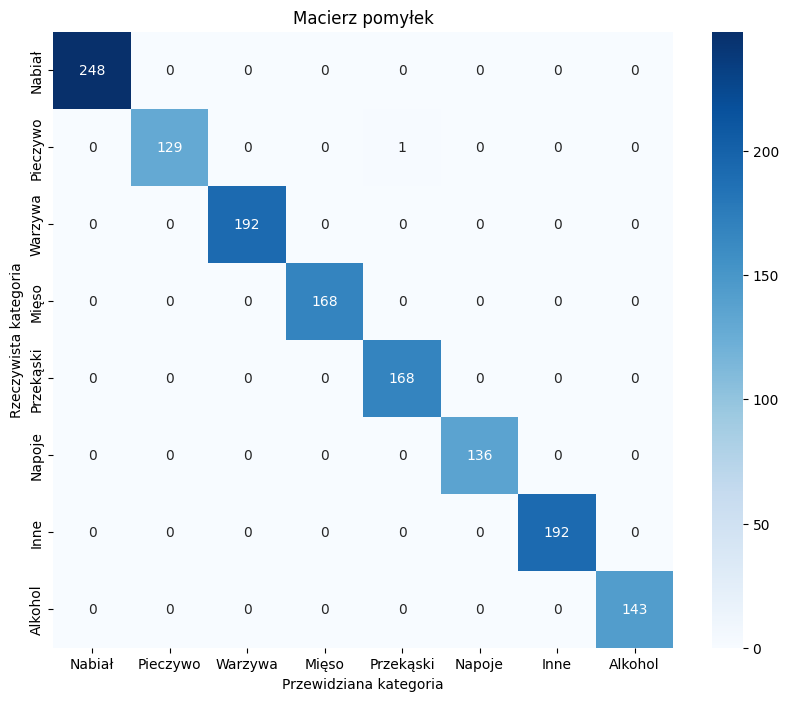

In [26]:
# Pobieranie predykcji dla całego zbioru testowego
model.eval()
with torch.no_grad():
    outputs = model(X_test)
    _, preds = torch.max(outputs, 1)

# Macierz pomyłek
cm = confusion_matrix(y_test.numpy(), preds.numpy())
kategorie_nazwy = ["Nabiał", "Pieczywo", "Warzywa", "Mięso", "Przekąski", "Napoje", "Inne", "Alkohol"]

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=kategorie_nazwy, yticklabels=kategorie_nazwy)
plt.xlabel('Przewidziana kategoria')
plt.ylabel('Rzeczywista kategoria')
plt.title('Macierz pomyłek')
plt.savefig('confusion_matrix.png') 

#  Zautomatyzowany System Analizy Paragonów

In [27]:
# Definicja Sieci Neuronowej
class SiecNeuronowa(nn.Module):
    def __init__(self, n_features, hidden_size, dropout_rate):
        super().__init__()
        self.fc1 = nn.Linear(n_features, hidden_size)
        self.bn1 = nn.BatchNorm1d(hidden_size)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_size, 8)

    def forward(self, x):
        if x.dim() == 1:
            x = x.unsqueeze(0)
        x = self.fc1(x)
        if x.size(0) > 1: x = self.bn1(x) 
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x
# Struktura danych przechowująca obraz paragonu i jego metadane
class ReceiptImage:   
    def __init__(self, filename: str, raw_data: np.ndarray, metadata: Dict[str, Any]):
        self.filename = filename
        self.raw_data = raw_data
        self.metadata = metadata
# Wczytywanie obrazu z dysku.
class RealImageLoader:
    def load(self, path):
        if not os.path.exists(path):
            raise FileNotFoundError(f"Nie znaleziono pliku: {path}")
        
        img_array = cv2.imread(path)
        if img_array is None:
             raise ValueError("Nie udało się wczytać obrazu.")

        return ReceiptImage(
            filename=path, 
            raw_data=img_array, 
            metadata={"source_path": path}
        )
# Preprocessing załadowanego zdjęcia
class Preprocessor:
    def process(self, image):
        img_array = image.raw_data
        img_rgb = cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB)
        img_for_osd = cv2.copyMakeBorder(
                img_rgb, 
                top=50, bottom=50, left=50, right=50, 
                borderType=cv2.BORDER_CONSTANT, 
                value=[255, 255, 255]
            )
        try:
            pil_image = Image.fromarray(img_for_osd)
            osd_info = pytesseract.image_to_osd(pil_image)
            angle_match = re.search(r"Rotate: (\d+)", osd_info)
            
            if angle_match:
                detected_angle = int(angle_match.group(1))
            else:
                detected_angle = 0
            
            if detected_angle != 0:
                logging.info(f"Obrót obrazu o {detected_angle} stopni.")
                (h, w) = img_array.shape[:2]
                center = (w // 2, h // 2)
                M = cv2.getRotationMatrix2D(center, 360 - detected_angle, 1.0)
                img_rotated = cv2.warpAffine(img_array, M, (w, h), 
                                             flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
            else:
                logging.info("Nie wykryto obrotu obrazu.")
                img_rotated = img_array
        except Exception as e:
            logging.error(f"Błąd podczas wykrywania obrotu: {e}.")
            img_rotated = img_array

        img_array = img_rotated

        height = img_array.shape[0]
        if height > 2500: 
            scale = 2500 / height
            dim = (int(img_array.shape[1] * scale), 2500)
            img_array = cv2.resize(img_array, dim, interpolation=cv2.INTER_AREA)

        gray = cv2.cvtColor(img_array, cv2.COLOR_BGR2GRAY)
        blurred = cv2.GaussianBlur(gray, (5, 5), 0)
        img_final = cv2.addWeighted(gray, 1.5, blurred, -0.5, 0)
        img_final = cv2.normalize(img_final, None, 0, 255, cv2.NORM_MINMAX)

        image.raw_data = img_final
        image.metadata["preprocessed"] = True
        return image

# Silnik ekstrakcji tekstu bazujący na Pytesseract
class RealOCREngine:
    def extract_text(self, image):
        logging.info("Krok 3: Ekstrakcja tekstu")
        img_array = image.raw_data
        custom_config = r'--oem 3 --psm 4'        
        text = pytesseract.image_to_string(img_array, lang='pol', config=custom_config)
        return text
# Parser pomagający przetworzyć zczytane linie ze zdjęcia i wyodrębnić tylko istotną część
class Parser:
    def czy_podobne(self, slowo1, wzorzec, prog=0.50):
        if not slowo1 or not wzorzec: return False
        return SequenceMatcher(None, slowo1.upper(), wzorzec.upper()).ratio() >= prog

    def czy_zawiera_fraze(self, linia, fraza):
        linia_norm = linia.upper().replace(" ", "")
        fraza_norm = fraza.upper().replace(" ", "")
        if fraza_norm in linia_norm: return True
        return self.czy_podobne(linia_norm, fraza_norm, prog=0.75)

    def parsuj_paragon_inteligentny(self, tekst_z_ocr):
        linie = tekst_z_ocr.split('\n')
        idx_paragon = -1
        idx_nip = -1
        idx_koniec = -1
        stop_words = ["SPRZEDAŻ", "OPODATKOWANA", "PODSUMA", "PODSUNA", "RAZEM PLN", "SUMA PLN", "PTU"]

        for i, linia in enumerate(linie):
            linia_upper = linia.upper().strip()
            if not linia_upper: continue

            if "NIEFISKALNY" not in linia_upper:
                if ("PARAGON" in linia_upper and "FISKALNY" in linia_upper) or \
                   self.czy_zawiera_fraze(linia, "PARAGON FISKALNY"):
                    idx_paragon = i

            if idx_nip == -1 and ("NIP" in linia_upper):
                if any(char.isdigit() for char in linia_upper):
                    idx_nip = i

            if idx_koniec == -1:
                if any(word in linia_upper for word in stop_words):
                    idx_koniec = i
                    break

        start_index = 0
        if idx_paragon != -1:
            start_index = idx_paragon + 1 
        elif idx_nip != -1:
            start_index = idx_nip + 1 
        else:
            start_index = 0

        if idx_koniec == -1:
            end_index = len(linie)
        else:
            end_index = idx_koniec

        if end_index <= start_index:
            end_index = len(linie)

        wybrane_linie = linie[start_index:end_index]
        return "\n".join(wybrane_linie)

    def wyodrebnij_tylko_produkty(self, tekst):
        if not tekst: return []
        linie = tekst.split('\n')
        czyste_produkty = []
        wzorzec_ceny = r'([0-9\s]*[ilI|]szt|iszt|lszt|[xX*«])\s*[\d,.]+'
        zakazane = r'(suma|sprzedaż|ptu|paragon|fiskalny|podsuma|gotówka|karta|reszta|kwota|pln|opust|rabat|zniżka|total|rozliczenie|adres|siedziby|nip|bdo|ul\.|sp\. z o\.o\.|woj\.|tel\.|nr rej|kierownik|kasjer)'

        linie_z_cena = sum(1 for l in linie if re.search(wzorzec_ceny, l))
        try:
            wspolczynnik_cen = linie_z_cena / len(linie)
        except ZeroDivisionError:
            wspolczynnik_cen = 0
            
        tryb_scisly = wspolczynnik_cen > 0.3 

        for linia in linie:
            linia = linia.strip()
            if len(linia) < 2: continue

            match = re.search(wzorzec_ceny, linia)
            produkt_do_dodania = ""

            if match:
                punkt_startu = match.start()
                if punkt_startu > 3: 
                    produkt_do_dodania = linia[:punkt_startu]
                else:
                    continue 
            else:
                if tryb_scisly:
                    continue 
                else:
                    produkt_do_dodania = linia

            produkt_do_dodania = re.sub(r'\s+[A-Z0-9]$', '', produkt_do_dodania) 
            produkt_do_dodania = re.sub(r'[\s\.\-_—,/]+$', '', produkt_do_dodania)
            produkt_do_dodania = re.sub(r'^[\-_.,\s]+', '', produkt_do_dodania)

            if len(produkt_do_dodania) >= 3 and not re.search(zakazane, produkt_do_dodania.lower()):
                czyste_produkty.append(produkt_do_dodania)
            
        return czyste_produkty
    
    def parse_text(self, text_content: str):
        blok_tekstu = self.parsuj_paragon_inteligentny(text_content)
        lista_surowa = self.wyodrebnij_tylko_produkty(blok_tekstu)
        return lista_surowa
# Klasyfikator zczytanych produktów dla ustalonych klas
class Classifier:
    def __init__(self, model_path="model_paragonowy.pth", config_path="model_config.json"):
        
        # Wczytujemy plik JSON z zapisanymi wygranymi parametrami z Optuny
        with open(config_path, 'r') as f:
            config = json.load(f)
            
        self.n_features = config['n_features'] 
        
        # Budujemy sieć DYNAMICZNIE na podstawie tego, co przeczytaliśmy z pliku
        self.model = SiecNeuronowa(
            n_features=config['n_features'], 
            hidden_size=config['hidden_size'], 
            dropout_rate=config['dropout_rate']
        )
        
        self.device = torch.device("cpu")
        self.kategorie_mapa = {
            0: "Nabiał", 1: "Pieczywo", 2: "Warzywa/Owoce", 3: "Mięso",
            4: "Przekąski", 5: "Napoje", 6: "Inne", 7: "Alkohol"
        }
        
        self.model.load_state_dict(torch.load(model_path, map_location=self.device))
        self.model.eval()

    def text_to_vector(self, text):
        text = str(text).lower().strip()
        vector = torch.zeros(self.n_features) 
        if len(text) < 3:
            text = text + "   " 
            
        for i in range(len(text) - 2):
            trigram = text[i:i+3]
            idx = murmurhash3_32(trigram, seed=42) % self.n_features
            vector[idx] += 1.0
        return vector

    def classify_single_product(self, nazwa_produktu):
        wektor = self.text_to_vector(nazwa_produktu)
        with torch.no_grad():
            output = self.model(wektor)
            probs = torch.nn.functional.softmax(output, dim=1)
            pewnosc, idx = torch.max(probs, 1)
        
        return self.kategorie_mapa.get(idx.item(), "Nieznane"), pewnosc.item()

    def classify(self, parsed_data):
        sklasyfikowane_produkty = []
        for prod in parsed_data:
            kat, pewnosc = self.classify_single_product(prod)
            
            sklasyfikowane_produkty.append({
                "nazwa": prod,
                "kategoria": kat,
                "pewnosc": f"{pewnosc*100:.0f}%"
            })
            
        return sklasyfikowane_produkty
# Wizualizacja wyników w czytelnej tabeli
class Visualizer:
    def show_comparison(self, image_data, items):
        fig, ax = plt.subplots(1, 2, figsize=(16, 9))
        fig.canvas.manager.set_window_title('System Analizy Paragonów - Wynik')
        
        if len(image_data.shape) == 2:
            ax[0].imshow(image_data, cmap='gray')
        else:
            img_rgb = cv2.cvtColor(image_data, cv2.COLOR_BGR2RGB)
            ax[0].imshow(img_rgb)
            
        ax[0].set_title("Przetworzony Paragon")
        ax[0].axis('off')

        ax[1].axis('off')
        ax[1].axis('tight')
 
        table_data = []
        col_labels = ["Produkt", "Kategoria"]
        
        for item in items:
            row = [item['nazwa'][:35], item['kategoria']]
            table_data.append(row)
            
        if not table_data:
            table_data = [["Brak produktów", "-", "-"]]

        table = ax[1].table(cellText=table_data, colLabels=col_labels, loc='center', cellLoc='left')
        
        table.auto_set_font_size(False)
        table.set_fontsize(11)
        table.scale(1, 1.8)
        
        ax[1].set_title(f"Wykryto produktów: {len(items)}")
        
        plt.tight_layout()
        plt.show()
# Pipeline
class ReceiptProcessingPipeline:
    def __init__(self, model_path="model_paragonowy.pth", config_path="model_config.json"):
        self.loader = RealImageLoader()
        self.preprocessor = Preprocessor()
        self.ocr_engine = RealOCREngine()
        self.parser = Parser()
        self.classifier = Classifier(model_path, config_path)
        self.visualizer = Visualizer()

    def run(self, image_path):
        img = self.loader.load(image_path)
        img = self.preprocessor.process(img)
        text = self.ocr_engine.extract_text(img)
        parsed_data = self.parser.parse_text(text)
        klasyfikacja = self.classifier.classify(parsed_data)
        
        image_to_show = img.metadata.get("display_image", img.raw_data)
        
        self.visualizer.show_comparison(image_to_show, klasyfikacja)

        finish = []
        for prod in klasyfikacja:
            position = {
                "produkt": prod["nazwa"],       
                "kategoria": prod["kategoria"]  
            }
            finish.append(position)
        return finish

# Funkcja Pomocnicza #

Funkcja pomocnicza do wizualizacji obrazu przed podaniem go do silnika OCR.
Pomaga w debugowaniu procesu preprocessingu (binaryzacji, odszumiania).

In [28]:
def pokaz_co_widzi_komputer(sciezka_lub_obraz):
    # Sprawdzamy, czy podano ścieżkę do pliku, czy już wczytany obraz 
    if isinstance(sciezka_lub_obraz, str):
        img = cv2.imread(sciezka_lub_obraz)
    else:
        img = sciezka_lub_obraz
        
    plt.figure(figsize=(10, 10))
    
    if len(img.shape) == 2: 
        plt.imshow(img, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        
    plt.title("Obraz przygotowany dla silnika Tesseract OCR")
    plt.axis('off') # Wyłączamy osie z numerkami pikseli
    plt.show()

 Surowe zdjęcie prosto z telefonu:


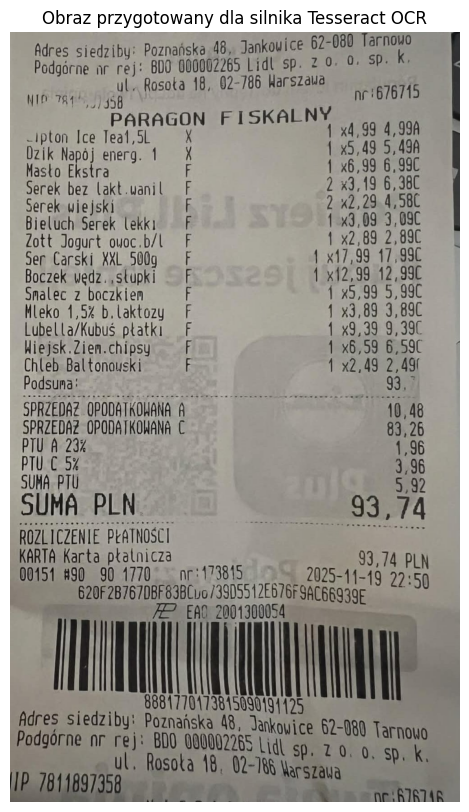

In [29]:
p7 = r"paragon_test3.jpg"

print(" Surowe zdjęcie prosto z telefonu:")
pokaz_co_widzi_komputer(p7)

# Przykladowe dzialanie #

ERROR: Błąd podczas wykrywania obrotu: (1, 'Estimating resolution as 133 Too few characters. Skipping this page Warning. Invalid resolution 0 dpi. Using 70 instead. Too few characters. Skipping this page Error during processing.').
INFO: Krok 3: Ekstrakcja tekstu


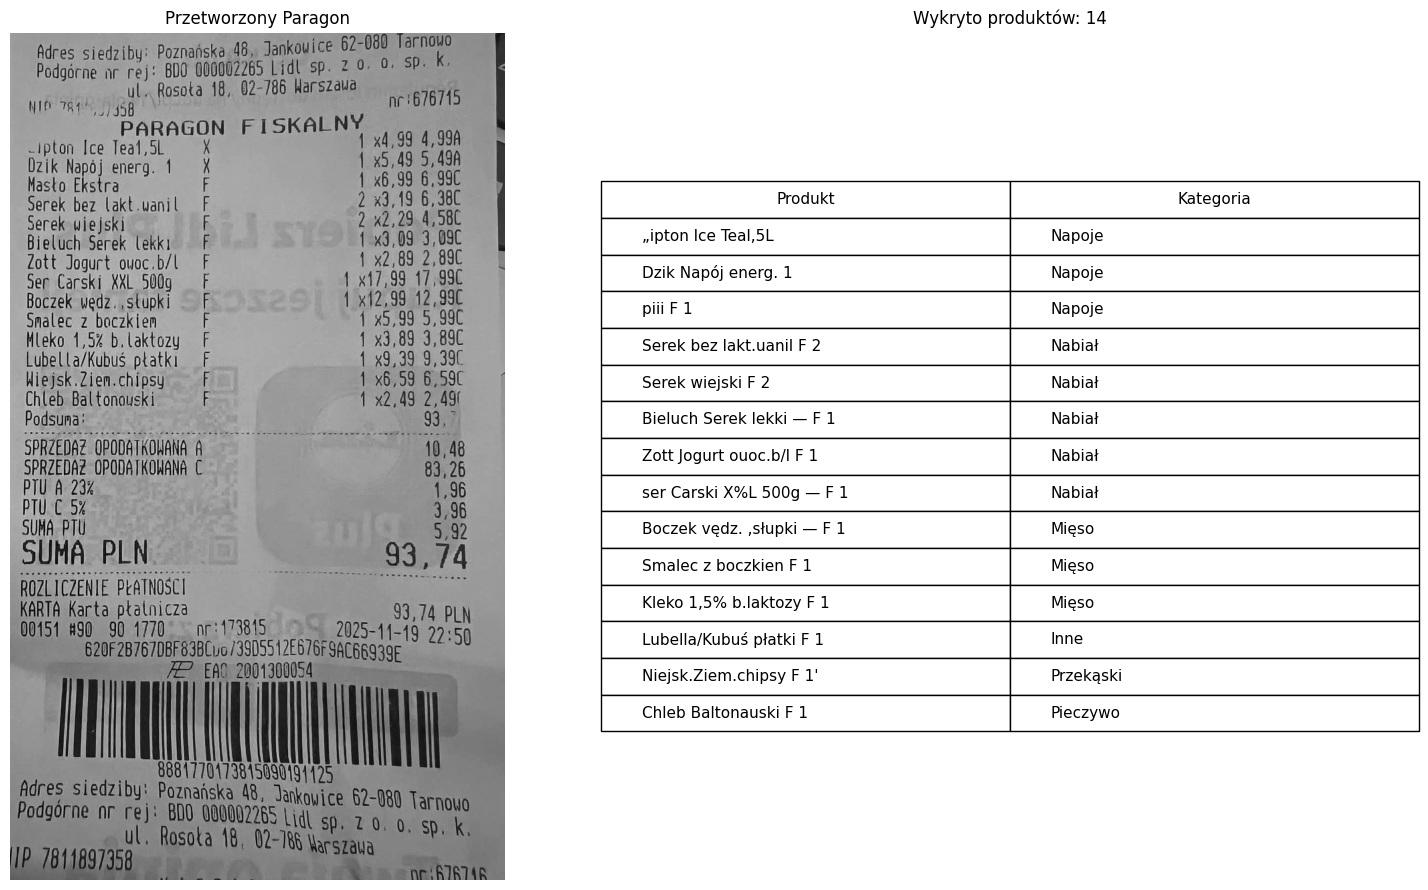

In [30]:
p7 = r"paragon_test3.jpg"

try:
    pipeline = ReceiptProcessingPipeline() 
    final_data = pipeline.run(p7)
    
except (FileNotFoundError, ValueError) as e:
    print(f"\nFATALNY BŁĄD: {e}")
except Exception as e:
    print(f"\nNieoczekiwany błąd: {e}")